# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

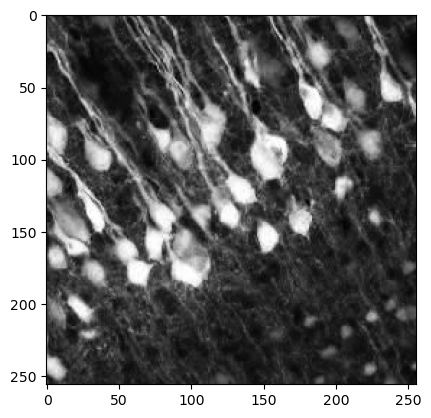

In [2]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [5]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

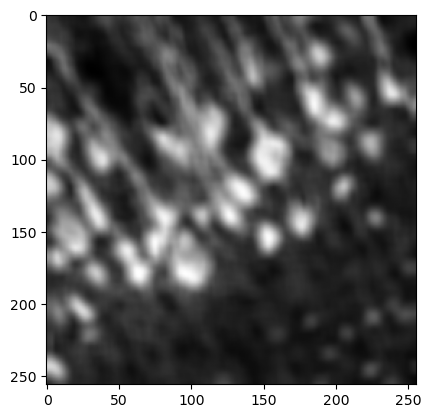

In [7]:
psf_img = conv(img, psf, mode='same', boundary='symm')

plt.imshow(psf_img, cmap = 'gray')

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

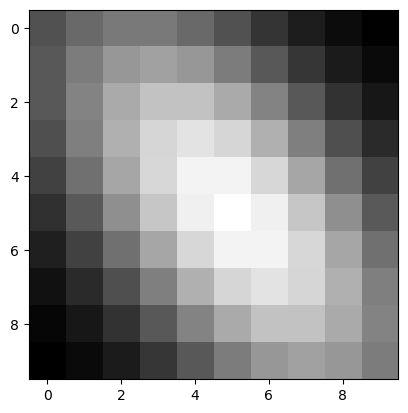

In [8]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

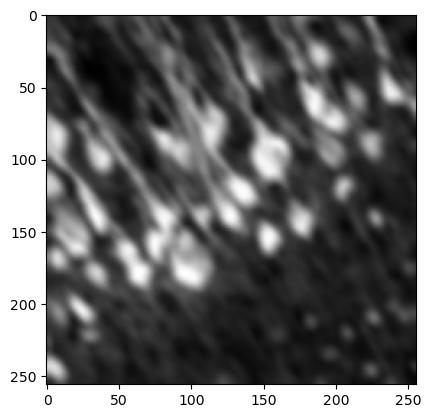

In [11]:
gaussian_psf = create_psf(psf_size)
gaus_img = conv(img, gaussian_psf, mode='same', boundary='symm')

plt.imshow(gaus_img, cmap = 'gray')

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [12]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    
    psf_flipped = np.flip(psf)

    for i in range(n_iterations):
        blurred_estimate = conv(img_deconv, psf,
                                mode='same', boundary='symm')

        ratio = image / np.maximum(blurred_estimate, 1e-12)

        correction = conv(ratio, psf_flipped,
                          mode='same', boundary='symm')

        img_deconv = img_deconv * correction
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [59]:
deconvolved_img_20 = richardson_lucy_deconvolution(psf_img, psf, 20)
deconvolved_img_50 = richardson_lucy_deconvolution(psf_img, psf, 50)
deconvolved_img_100 = richardson_lucy_deconvolution(psf_img, psf, 100)
deconvolved_img_200 = richardson_lucy_deconvolution(psf_img, psf, 200)


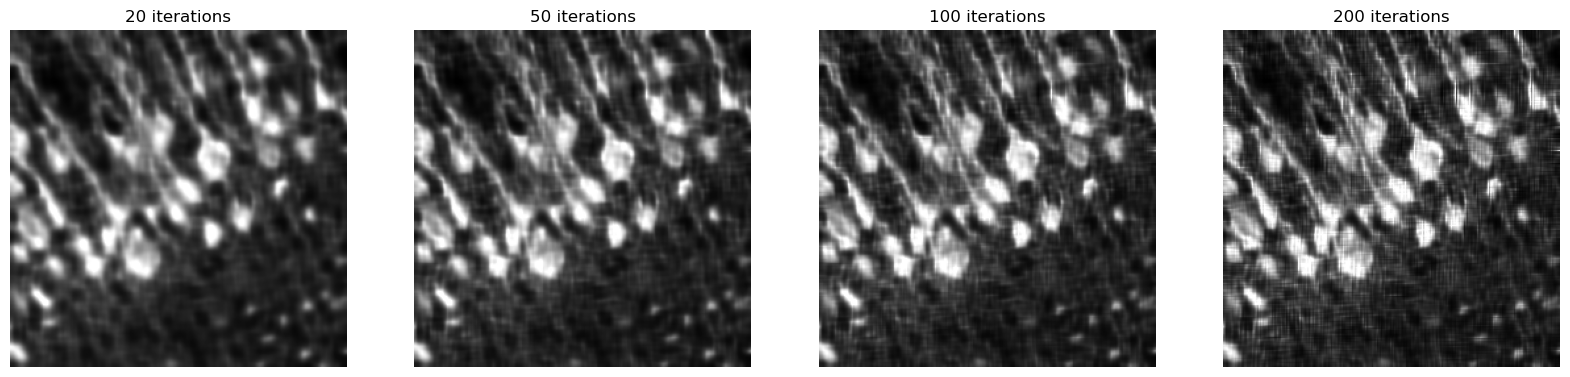

In [68]:
plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(deconvolved_img_20, 'gray')
plt.title('20 iterations')
plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(deconvolved_img_50, 'gray')
plt.title('50 iterations')
plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(deconvolved_img_100, 'gray')
plt.title('100 iterations')
plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(deconvolved_img_200, 'gray')
plt.title('200 iterations')

plt.show()

For more iterations -> more definition, but also more noise

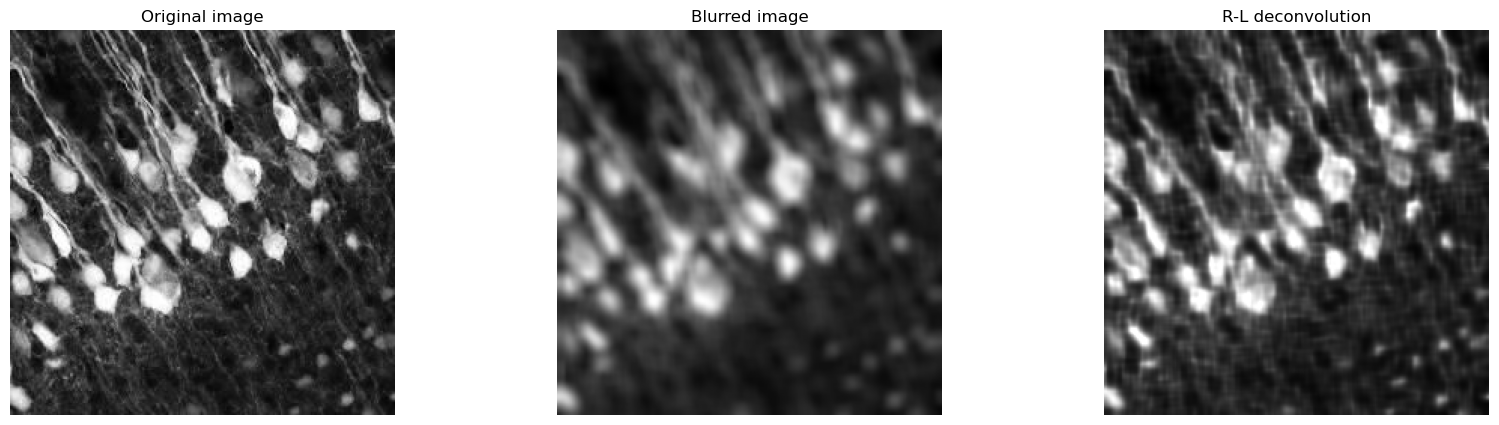

In [ ]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(psf_img, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconvolved_img_50, 'gray')
plt.title('R-L deconvolution')

plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [70]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor_1 = 10
reduce_factor_2 = 30
noise_1 = noise / reduce_factor_1
noise_2 = noise / reduce_factor_2

In [71]:
noise_img_1 = psf_img + noise_1
noise_img_2 = psf_img + noise_2
noise_img_1 = np.clip(noise_img_1, 0, 1)
noise_img_2 = np.clip(noise_img_2, 0, 1)
deconvolved_noisy_img_1 = richardson_lucy_deconvolution(noise_img_1, psf, 50)
deconvolved_noisy_img_2 = richardson_lucy_deconvolution(noise_img_2, psf, 50)

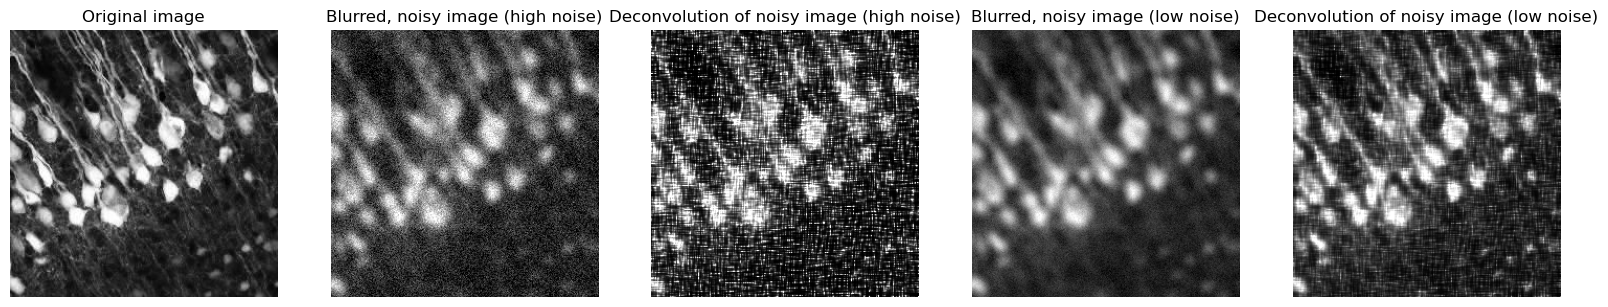

In [72]:
plt.figure(figsize=(20,5))
plt.subplot(1, 5, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 5, 2)
plt.axis('off')
plt.imshow(noise_img_1, 'gray')
plt.title('Blurred, noisy image (high noise)')
plt.subplot(1, 5, 3)
plt.axis('off')
plt.imshow(deconvolved_noisy_img_1, 'gray')
plt.title('Deconvolution of noisy image (high noise)')
plt.subplot(1, 5, 4)
plt.axis('off')
plt.imshow(noise_img_2, 'gray')
plt.title('Blurred, noisy image (low noise)')
plt.subplot(1, 5, 5)
plt.axis('off')
plt.imshow(deconvolved_noisy_img_2, 'gray')
plt.title('Deconvolution of noisy image (low noise)')

    
plt.show()

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

In [73]:
wiener_deconv_img_1 = wiener(noise_img_1, psf, balance=2, clip=True)
wiener_deconv_img_2 = wiener(noise_img_2, psf, balance=2, clip=True)

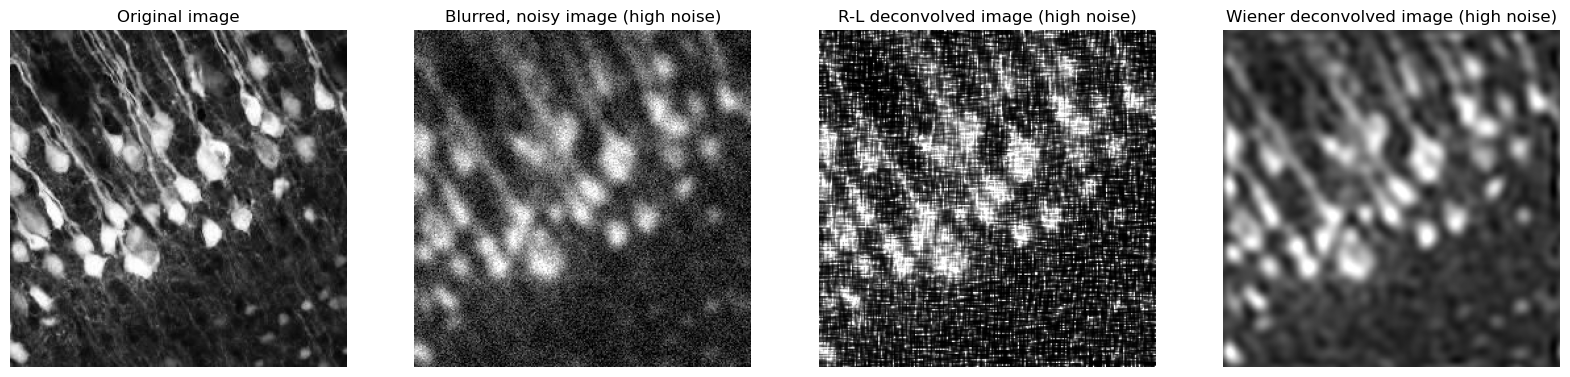

In [76]:
plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(noise_img_1, 'gray')
plt.title('Blurred, noisy image (high noise)')
plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(deconvolved_noisy_img_1, 'gray')
plt.title('R-L deconvolved image (high noise)')
plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(wiener_deconv_img_1, 'gray')
plt.title('Wiener deconvolved image (high noise)')

plt.show()

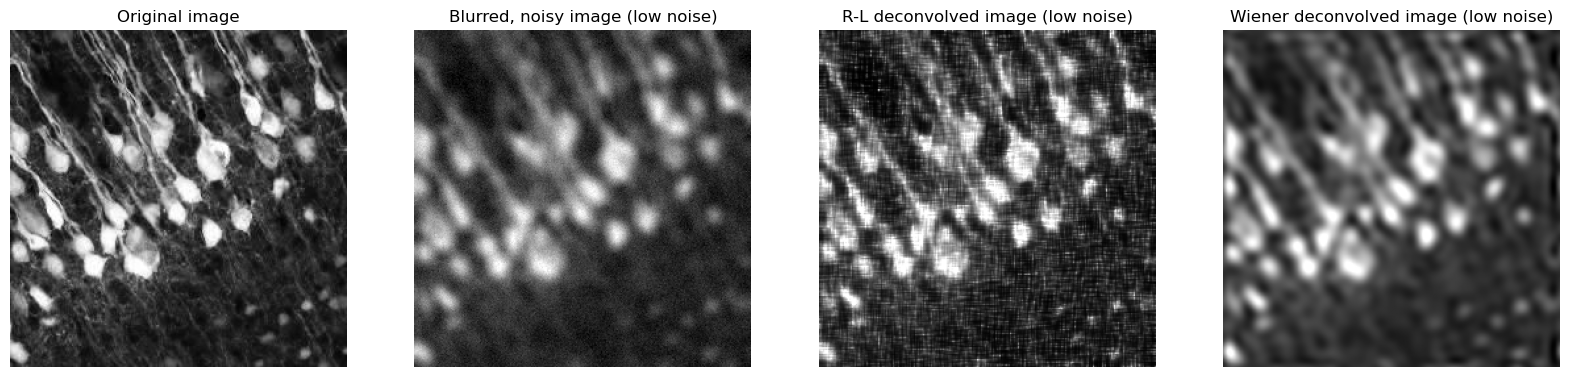

In [77]:
plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(noise_img_2, 'gray')
plt.title('Blurred, noisy image (low noise)')
plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(deconvolved_noisy_img_2, 'gray')
plt.title('R-L deconvolved image (low noise)')
plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(wiener_deconv_img_2, 'gray')
plt.title('Wiener deconvolved image (low noise)')

plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

In [93]:
psf_2_size = 5
psf_2 = np.ones((psf_2_size, psf_2_size)) / psf_2_size ** 2

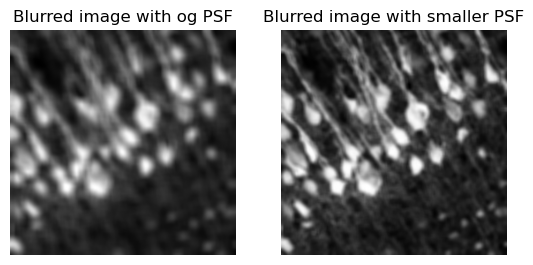

In [94]:
psf_img_2 = conv(img, psf_2, mode='same', boundary='symm')

plt.figure()
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(psf_img, cmap = 'gray')
plt.title('Blurred image with og PSF')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(psf_img_2, cmap = 'gray')
plt.title('Blurred image with smaller PSF')

plt.show()

In [96]:
#only doing it with iteration number = 50
deconvolved_img_50_2 = richardson_lucy_deconvolution(psf_img_2, psf_2, 50)

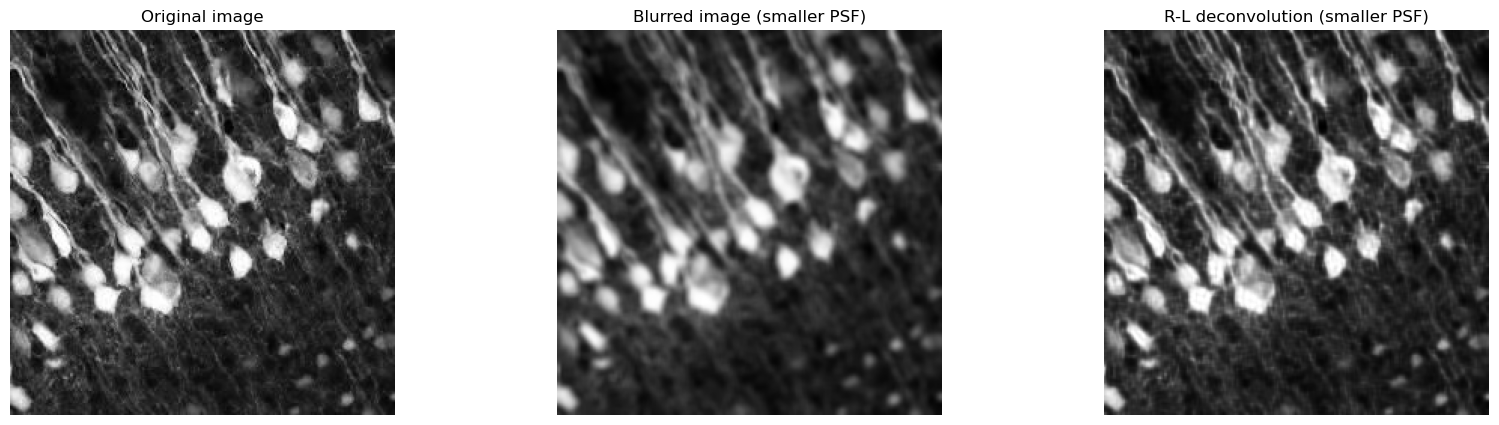

In [97]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(psf_img_2, 'gray')
plt.title('Blurred image (smaller PSF)')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconvolved_img_50_2, 'gray')
plt.title('R-L deconvolution (smaller PSF)')

plt.show()

In [98]:
#adding noise to the image with smaller PSF and deconvolving it

low_psf_img_noise_1 = psf_img_2 + noise_1
low_psf_img_noise_2 = psf_img_2 + noise_2

low_psf_img_noise_1 = np.clip(low_psf_img_noise_1, 0, 1)
low_psf_img_noise_2 = np.clip(low_psf_img_noise_2, 0, 1)

deconvolved_low_psf_img_noise_1 = richardson_lucy_deconvolution(low_psf_img_noise_1, psf_2, 50)
deconvolved_low_psf_img_noise_2 = richardson_lucy_deconvolution(low_psf_img_noise_2, psf_2, 50)



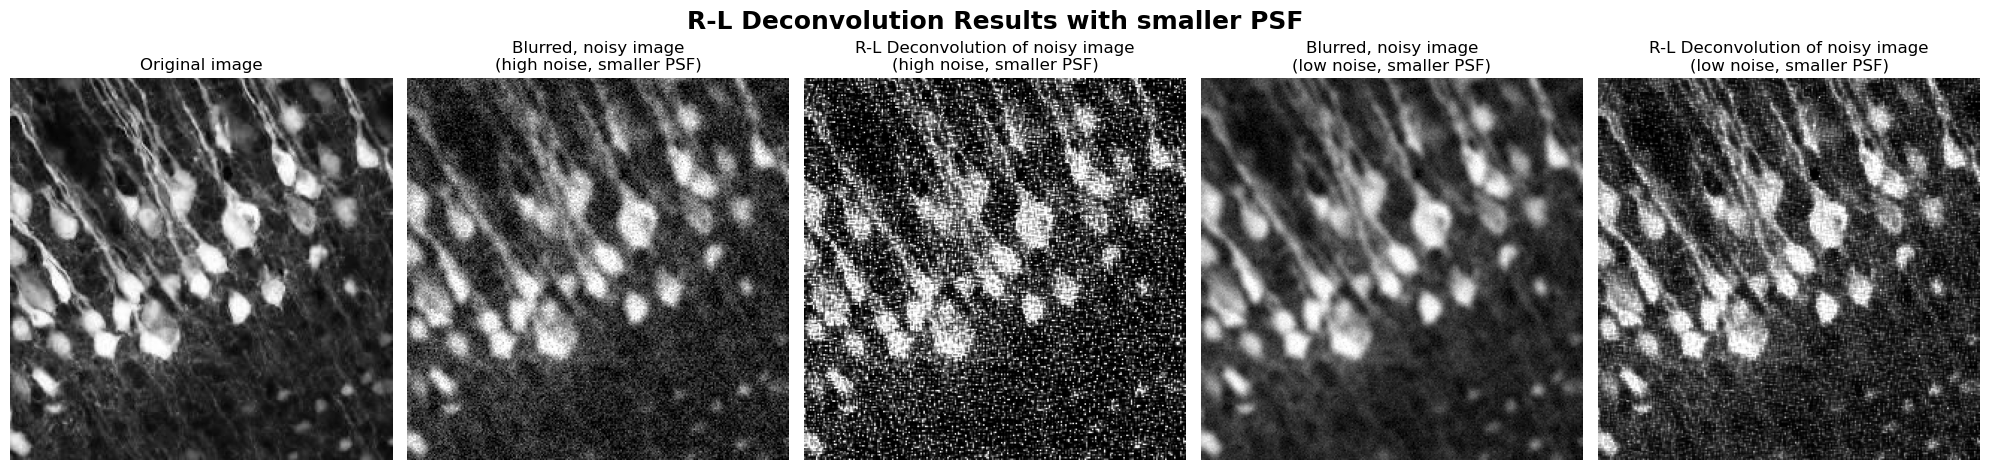

In [111]:
plt.figure(figsize=(20,5))
plt.subplot(1, 5, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 5, 2)
plt.axis('off')
plt.imshow(low_psf_img_noise_1, 'gray')
plt.title('Blurred, noisy image\n(high noise, smaller PSF)')

plt.subplot(1, 5, 3)
plt.axis('off')
plt.imshow(deconvolved_low_psf_img_noise_1, 'gray')
plt.title('R-L Deconvolution of noisy image\n(high noise, smaller PSF)')

plt.subplot(1, 5, 4)
plt.axis('off')
plt.imshow(low_psf_img_noise_2, 'gray')
plt.title('Blurred, noisy image\n(low noise, smaller PSF)')

plt.subplot(1, 5, 5)
plt.axis('off')
plt.imshow(deconvolved_low_psf_img_noise_2, 'gray')
plt.title('R-L Deconvolution of noisy image\n(low noise, smaller PSF)')

plt.suptitle('R-L Deconvolution Results with smaller PSF', fontsize=18, fontweight='bold')

plt.tight_layout()
plt.show()

In [109]:
#comparing R-L deconv (small PSF) with Wiener deconv (small PSF)

wiener_deconv_low_psf_img_1 = wiener(low_psf_img_noise_1, psf_2, balance=2, clip=True)
wiener_deconv_low_psf_img_2 = wiener(low_psf_img_noise_2, psf_2, balance=2, clip=True)

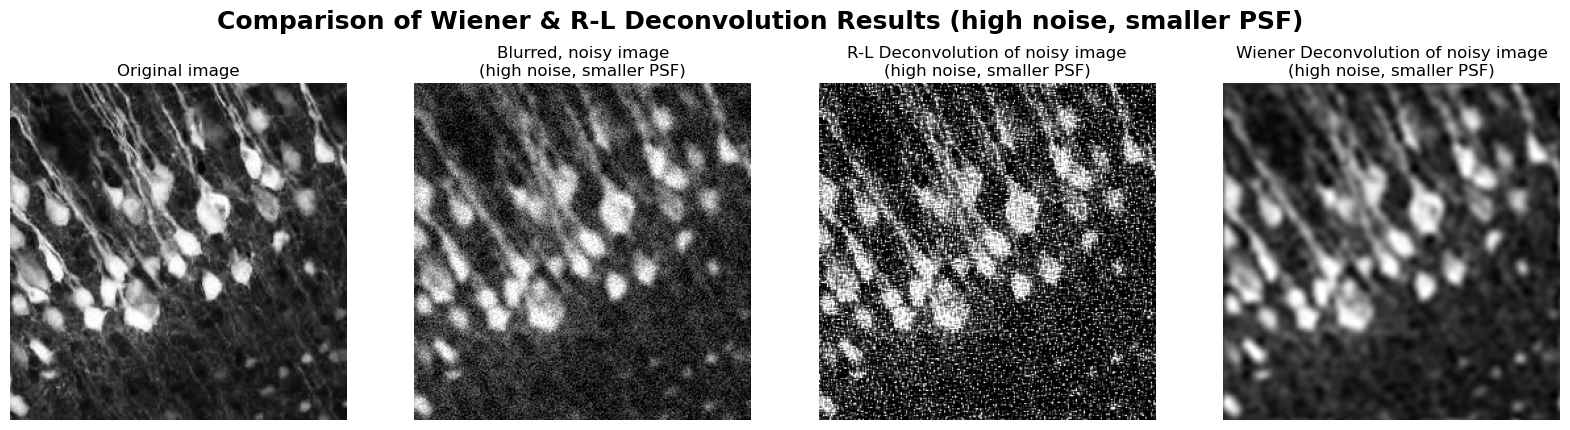

In [ ]:
#plotting comparison (high noise)

plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(low_psf_img_noise_1, 'gray')
plt.title('Blurred, noisy image\n(high noise, smaller PSF)')

plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(deconvolved_low_psf_img_noise_1, 'gray')
plt.title('R-L Deconvolution of noisy image\n(high noise, smaller PSF)')

plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(wiener_deconv_low_psf_img_1, 'gray')
plt.title('Wiener Deconvolution of noisy image\n(high noise, smaller PSF)')


plt.suptitle('Comparison of Wiener & R-L Deconvolution Results (high noise, smaller PSF)', fontsize=18, fontweight='bold')

plt.show()

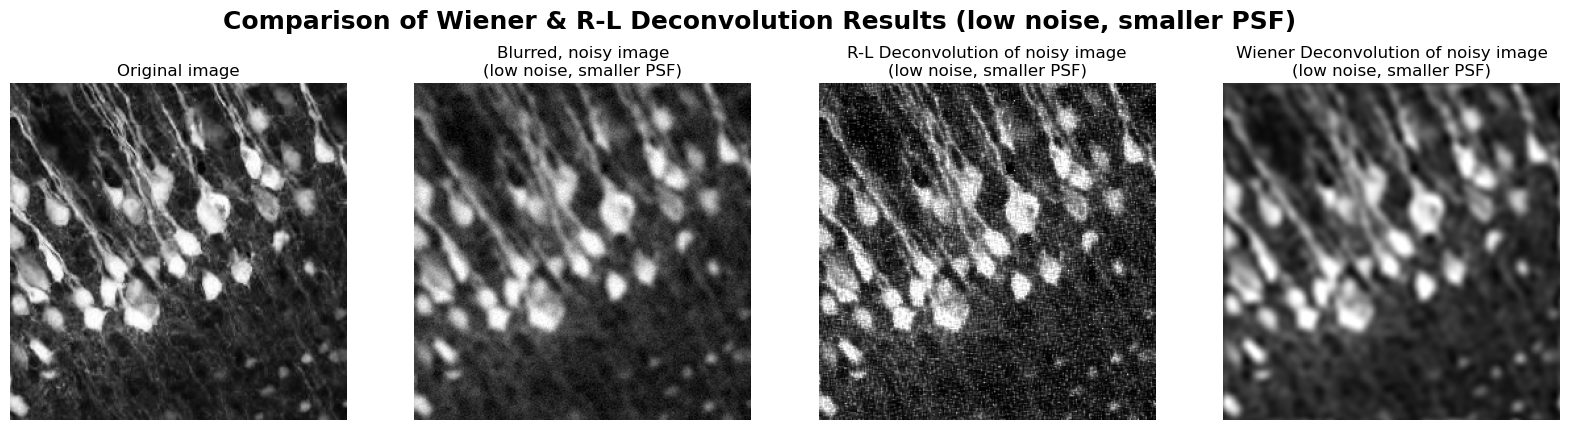

In [114]:
#plotting comparison (low noise)

plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(low_psf_img_noise_2, 'gray')
plt.title('Blurred, noisy image\n(low noise, smaller PSF)')

plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(deconvolved_low_psf_img_noise_2, 'gray')
plt.title('R-L Deconvolution of noisy image\n(low noise, smaller PSF)')

plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(wiener_deconv_low_psf_img_2, 'gray')
plt.title('Wiener Deconvolution of noisy image\n(low noise, smaller PSF)')


plt.suptitle('Comparison of Wiener & R-L Deconvolution Results (low noise, smaller PSF)', fontsize=18, fontweight='bold')

plt.show()


**[Task 8.]()** Use a wrong PSF to restore the image

In [115]:
psf_blur_gaussian_psf_deconv = richardson_lucy_deconvolution(psf_img, gaussian_psf, 50)
gaussian_psf_blur_psf_deconv = richardson_lucy_deconvolution(gaus_img, psf, 50)

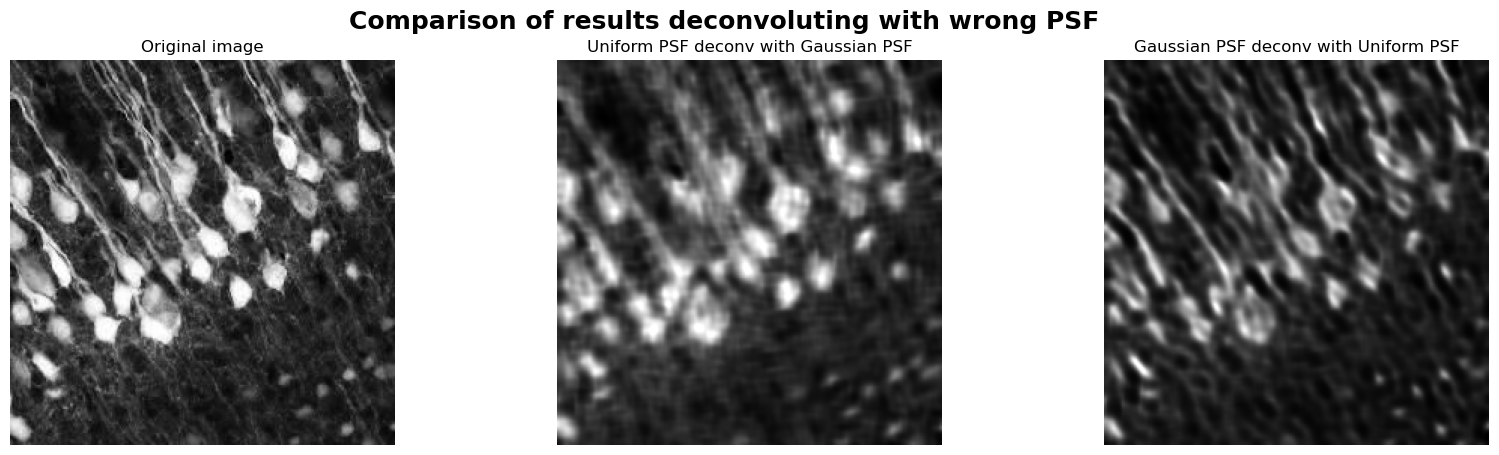

In [120]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(psf_blur_gaussian_psf_deconv, cmap = 'gray')
plt.title('Uniform PSF deconv with Gaussian PSF')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(gaussian_psf_blur_psf_deconv, cmap = 'gray')
plt.title('Gaussian PSF deconv with Uniform PSF')

plt.suptitle('Comparison of results deconvoluting with wrong PSF', fontsize=18, fontweight='bold')
plt.tight_layout
plt.show()

